# Netflix Content Segmentation

This project uses unsupervised machine learning to group Netflix titles into meaningful clusters based on content features.

## Project Workflow

1. Load the dataset
2. Select relevant features
3. Handle missing values
4. Encode categorical features
5. Scale numerical features
6. Apply K-Means clustering
7. Analyze the clusters
8. Visualize clusters using PCA
9. Evaluate clustering performance using the Silhouette Score

In [1]:
import pandas as pd

df = pd.read_csv("Dataset.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [2]:
features = ['type', 'release_year', 'country', 'listed_in']
X = df[features].copy()
X.head()

,type,release_year,country,listed_in
0,Movie,2020,United States,Documentaries
1,TV Show,2021,France,"Crime TV Shows, International TV Shows, TV Act..."
2,TV Show,2021,United States,"TV Dramas, TV Horror, TV Mysteries"
3,Movie,2021,Brazil,"Children & Family Movies, Comedies"
4,Movie,1993,United States,"Dramas, Independent Movies, International Movies"


In [3]:
X['country'] = X['country'].fillna('Unknown')
X['listed_in'] = X['listed_in'].fillna('Unknown')
X['release_year'] = X['release_year'].fillna(X['release_year'].median())

X.head()

,type,release_year,country,listed_in
0,Movie,2020,United States,Documentaries
1,TV Show,2021,France,"Crime TV Shows, International TV Shows, TV Act..."
2,TV Show,2021,United States,"TV Dramas, TV Horror, TV Mysteries"
3,Movie,2021,Brazil,"Children & Family Movies, Comedies"
4,Movie,1993,United States,"Dramas, Independent Movies, International Movies"


In [4]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = ['type', 'country', 'listed_in']
numeric_features = ['release_year']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numeric_features)
    ]
)
X_encoded = preprocessor.fit_transform(X)

print("Encoded data shape:", X_encoded.shape)

Encoded data shape: (8790, 602)


In [5]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_encoded)
df['cluster'] = clusters

print("Clustering completed successfully!")
print(df['cluster'].value_counts().sort_index())

Clustering completed successfully!
cluster
0    1931
1    3274
2     801
3    2574
4     210
Name: count, dtype: int64


In [6]:
cluster_summary = df.groupby('cluster').agg(
    total_titles=('title', 'count'),
    movies=('type', lambda x: (x == 'Movie').sum()),
    tv_shows=('type', lambda x: (x == 'TV Show').sum()),
    avg_release_year=('release_year', 'mean')
)

cluster_summary

,total_titles,movies,tv_shows,avg_release_year
cluster,,,,
0,1931,1931,0,2016.131020
1,3274,3274,0,2016.526878
2,801,724,77,2000.179775
3,2574,0,2574,2017.396270
4,210,197,13,1973.761905


In [7]:
for i in range(5):
    print("\nCluster:", i)
    print(df[df['cluster'] == i]['listed_in'].value_counts().head(5))


Cluster: 0
listed_in
Documentaries                         262
Stand-Up Comedy                       196
Children & Family Movies               88
Children & Family Movies, Comedies     88
Comedies                               76
Name: count, dtype: int64

Cluster: 1
listed_in
Dramas, International Movies                        320
Dramas, Independent Movies, International Movies    229
Comedies, Dramas, International Movies              228
Documentaries, International Movies                 163
Comedies, International Movies                      159
Name: count, dtype: int64

Cluster: 2
listed_in
Children & Family Movies, Comedies        39
Comedies, Dramas, International Movies    39
Dramas, International Movies              35
Action & Adventure                        30
Comedies, Romantic Movies                 28
Name: count, dtype: int64

Cluster: 3
listed_in
Kids' TV                                                  203
International TV Shows, TV Dramas                        

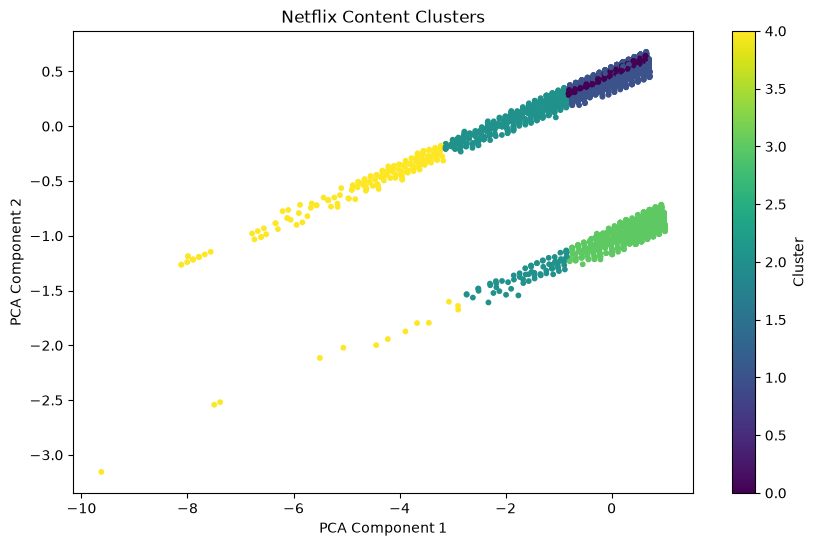

In [10]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_encoded.toarray())

plt.figure(figsize=(10, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap='viridis',
    s=10
)

plt.title("Netflix Content Clusters")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label="Cluster")
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_encoded, clusters)
print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.142


## Conclusion

In this project, I used K-Means clustering to group Netflix titles based on content type, release year, country, and genres.

I prepared the dataset by handling missing values, encoding categorical features, and scaling numerical data.

I created five clusters and analyzed their size, content types, and most common genres.

I also used PCA to visualize the clusters in two dimensions and evaluated the clustering performance using the Silhouette Score.

The Silhouette Score was 0.142, indicating that the clusters have limited separation. This suggests that the selected features and clustering method could be improved in future work.